# Advanced Multi-Source Data Pipeline Scrape

In [68]:
import requests
from bs4 import BeautifulSoup
import json
from dotenv import load_dotenv
import pandas as pd
import numpy as np
import os
import time 

In [27]:
pip install beautifulsoup4 requests pandas 

Note: you may need to restart the kernel to use updated packages.


In [28]:
load_dotenv()

api_key = os.getenv("cryptocurrency_market_api_key")

url = "https://api.coingecko.com/api/v3/coins/markets"

headers = {
    "x-cg-demo-api-key": api_key
}

all_data = []

for page in range(1, 6):

    params = {
        "vs_currency": "usd",
        "order": "market_cap_desc",
        "per_page": 100,
        "page": page
    }

    response = requests.get(
        url,
        params=params,
        headers=headers
    )

    print("Page:", page, "Status:", response.status_code)

    # Check if request was successful
    if response.status_code == 200:

        data = response.json()

        # Make sure data is a list
        if isinstance(data, list):
            all_data.extend(data)
        else:
            print("Unexpected response:", data)

    else:
        print("Error:", response.text)

    time.sleep(1)

df = pd.DataFrame(all_data)

print("Total rows:", len(df))
print(df.head())

Page: 1 Status: 200
Page: 2 Status: 200
Page: 3 Status: 200
Page: 4 Status: 200
Page: 5 Status: 200
Total rows: 500
            id symbol      name  \
0      bitcoin    btc   Bitcoin   
1     ethereum    eth  Ethereum   
2       tether   usdt    Tether   
3  binancecoin    bnb       BNB   
4       ripple    xrp       XRP   

                                               image  current_price  \
0  https://coin-images.coingecko.com/coins/images...       79921.00   
1  https://coin-images.coingecko.com/coins/images...        2502.35   
2  https://coin-images.coingecko.com/coins/images...           1.00   
3  https://coin-images.coingecko.com/coins/images...         761.48   
4  https://coin-images.coingecko.com/coins/images...           1.42   

      market_cap  market_cap_rank  fully_diluted_valuation  total_volume  \
0  1604966954634              1.0             1.604976e+12  1.899971e+10   
1   305336963529              2.0             3.053443e+11  7.612499e+09   
2   183404498110  

In [29]:
df

,id,symbol,name,image,current_price,market_cap,market_cap_rank,fully_diluted_valuation,total_volume,high_24h,...,total_supply,max_supply,ath,ath_change_percentage,ath_date,atl,atl_change_percentage,atl_date,roi,last_updated
0,bitcoin,btc,Bitcoin,https://coin-images.coingecko.com/coins/images...,79921.000000,1604966954634,1.0,1.604976e+12,1.899971e+10,80147.000000,...,2.008030e+07,2.100000e+07,126080.000000,-36.61047,2025-10-06T10:57:42.000Z,67.810000,1.177626e+05,2013-07-05T16:00:00.000Z,None,2026-09-06T02:23:20.000Z
1,ethereum,eth,Ethereum,https://coin-images.coingecko.com/coins/images...,2502.350000,305336963529,2.0,3.053443e+11,7.612499e+09,2508.340000,...,1.220239e+08,NaN,4946.050000,-49.40714,2025-08-24T11:21:03.000Z,0.432979,5.778376e+05,2015-10-19T16:00:00.000Z,"{'times': 40.853027331067345, 'currency': 'btc...",2026-09-06T02:23:20.000Z
2,tether,usdt,Tether,https://coin-images.coingecko.com/coins/images...,1.000000,183404498110,3.0,1.888718e+11,4.041956e+10,1.000000,...,1.888593e+11,NaN,1.320000,-24.41545,2018-07-23T16:00:00.000Z,0.572521,7.467581e+01,2015-03-01T16:00:00.000Z,None,2026-09-06T02:23:20.000Z
3,binancecoin,bnb,BNB,https://coin-images.coingecko.com/coins/images...,761.480000,101407074093,4.0,1.014071e+11,2.274317e+09,779.700000,...,1.331619e+08,2.000000e+08,1369.990000,-44.41727,2025-10-13T00:41:24.000Z,0.039818,1.912313e+06,2017-10-18T16:00:00.000Z,None,2026-09-06T02:23:20.000Z
4,ripple,xrp,XRP,https://coin-images.coingecko.com/coins/images...,1.420000,88873820650,5.0,1.416236e+11,1.499703e+09,1.430000,...,9.998563e+10,1.000000e+11,3.650000,-61.15667,2025-07-17T19:40:53.000Z,0.002686,5.262769e+04,2014-05-21T16:00:00.000Z,None,2026-09-06T02:23:20.000Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,altlayer,alt,AltLayer,https://coin-images.coingecko.com/coins/images...,0.006502,46327843,482.0,6.500886e+07,3.632967e+06,0.006576,...,1.000000e+10,1.000000e+10,0.676743,-99.03922,2024-03-28T15:20:10.000Z,0.005366,2.117851e+01,2026-06-06T05:03:15.000Z,None,2026-09-06T02:24:30.000Z
496,verge,xvg,Verge,https://coin-images.coingecko.com/coins/images...,0.002800,46298358,483.0,4.639097e+07,6.411714e+06,0.003190,...,1.655500e+10,NaN,0.261874,-98.93061,2017-12-23T16:00:00.000Z,0.000002,1.252228e+05,2015-02-05T16:00:00.000Z,None,2026-09-06T02:24:30.000Z
497,loaded-lions,lion,Loaded Lions,https://coin-images.coingecko.com/coins/images...,0.001508,46261213,484.0,1.507862e+08,2.113400e+04,0.001504,...,1.000000e+11,1.000000e+11,0.031592,-95.22716,2025-08-27T18:22:49.000Z,0.001196,2.610808e+01,2026-08-08T08:00:40.000Z,None,2026-09-06T02:24:30.000Z
498,pentagon-chain,pc,Pentagon Chain,https://coin-images.coingecko.com/coins/images...,46.970000,46182406,485.0,4.696841e+07,1.958470e+03,46.960000,...,1.000000e+06,NaN,58.590000,-19.83423,2026-05-18T22:15:00.000Z,11.680000,3.021324e+02,2025-06-16T14:54:20.000Z,None,2026-09-06T02:24:30.000Z


In [30]:
df.shape

(500, 26)

In [31]:
df.isna().sum()

id                                    0
symbol                                0
name                                  0
image                                 0
current_price                         0
market_cap                            0
market_cap_rank                       2
fully_diluted_valuation               0
total_volume                          0
high_24h                              0
low_24h                               0
price_change_24h                     13
price_change_percentage_24h          13
market_cap_change_24h                13
market_cap_change_percentage_24h     13
circulating_supply                    0
total_supply                          0
max_supply                          207
ath                                   0
ath_change_percentage                 0
ath_date                              0
atl                                   0
atl_change_percentage                 0
atl_date                              0
roi                                 460


In [32]:
df.columns

Index(['id', 'symbol', 'name', 'image', 'current_price', 'market_cap',
       'market_cap_rank', 'fully_diluted_valuation', 'total_volume',
       'high_24h', 'low_24h', 'price_change_24h',
       'price_change_percentage_24h', 'market_cap_change_24h',
       'market_cap_change_percentage_24h', 'circulating_supply',
       'total_supply', 'max_supply', 'ath', 'ath_change_percentage',
       'ath_date', 'atl', 'atl_change_percentage', 'atl_date', 'roi',
       'last_updated'],
      dtype='str')

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 26 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                500 non-null    str    
 1   symbol                            500 non-null    str    
 2   name                              500 non-null    str    
 3   image                             500 non-null    str    
 4   current_price                     500 non-null    float64
 5   market_cap                        500 non-null    int64  
 6   market_cap_rank                   498 non-null    float64
 7   fully_diluted_valuation           500 non-null    float64
 8   total_volume                      500 non-null    float64
 9   high_24h                          500 non-null    float64
 10  low_24h                           500 non-null    float64
 11  price_change_24h                  487 non-null    float64
 12  price_change_percen

In [34]:
df['market_cap_rank'] = df['market_cap_rank'].fillna(df['market_cap_rank'].mean())

In [35]:
df['market_cap_rank'].isna().sum()

np.int64(0)

In [36]:
df['price_change_24h'] = df['price_change_24h'].fillna(df['price_change_24h'].mean())
df['price_change_24h'].isna().sum()

np.int64(0)

In [37]:
df['price_change_percentage_24h'] = df['price_change_percentage_24h'].fillna(df['price_change_percentage_24h'].mean())
df['price_change_percentage_24h'].isna().sum()

np.int64(0)

In [38]:
df.isna().sum()

id                                    0
symbol                                0
name                                  0
image                                 0
current_price                         0
market_cap                            0
market_cap_rank                       0
fully_diluted_valuation               0
total_volume                          0
high_24h                              0
low_24h                               0
price_change_24h                      0
price_change_percentage_24h           0
market_cap_change_24h                13
market_cap_change_percentage_24h     13
circulating_supply                    0
total_supply                          0
max_supply                          207
ath                                   0
ath_change_percentage                 0
ath_date                              0
atl                                   0
atl_change_percentage                 0
atl_date                              0
roi                                 460


In [39]:
df['market_cap_change_24h'] = df['market_cap_change_24h'].fillna(df['market_cap_change_24h'].mean())
df['market_cap_change_24h'].isna().sum()

np.int64(0)

In [40]:
df['market_cap_change_percentage_24h'] = df['market_cap_change_percentage_24h'].fillna(df['market_cap_change_percentage_24h'].mean())
df['market_cap_change_percentage_24h'].isna().sum()

np.int64(0)

In [41]:
df['max_supply'] = df['max_supply'].fillna(df['max_supply'].mean())
df['max_supply'].isna().sum()

np.int64(0)

In [42]:
df['roi'] = df['roi'].fillna(df['roi'].mode())
df['roi'].isna().sum()

C:\Users\anilr\AppData\Local\Temp\ipykernel_7076\966367544.py:1: UserWarning: Unable to sort modes: '<' not supported between instances of 'dict' and 'dict'
  df['roi'] = df['roi'].fillna(df['roi'].mode())


np.int64(422)

In [43]:
df['roi'].value_counts()

roi
{'times': 40.853027331067345, 'currency': 'btc', 'percentage': 4085.3027331067346}       2
{'times': 16.329983925142997, 'currency': 'usd', 'percentage': 1632.9983925142997}       2
{'times': 10.345906506450167, 'currency': 'eth', 'percentage': 1034.5906506450167}       2
{'times': -0.9604382434300297, 'currency': 'usd', 'percentage': -96.04382434300297}      2
{'times': 7.350401674693775, 'currency': 'usd', 'percentage': 735.0401674693775}         2
{'times': 14.80690777837619, 'currency': 'usd', 'percentage': 1480.690777837619}         2
{'times': -0.025426975298136, 'currency': 'eth', 'percentage': -2.5426975298136}         2
{'times': 0.49015069436700265, 'currency': 'eth', 'percentage': 49.015069436700266}      2
{'times': 1.2241037148125884, 'currency': 'usd', 'percentage': 122.41037148125884}       2
{'times': 0.922976022650406, 'currency': 'usd', 'percentage': 92.2976022650406}          2
{'times': -0.4929033569452583, 'currency': 'usd', 'percentage': -49.29033569452583}   

In [44]:
print(df['roi'].head())
print(df['roi'].dtype)

0    {'times': 40.853027331067345, 'currency': 'btc...
1    {'times': 40.853027331067345, 'currency': 'btc...
2    {'times': 16.329983925142997, 'currency': 'usd...
3    {'times': 10.345906506450167, 'currency': 'eth...
4    {'times': -0.9604382434300297, 'currency': 'us...
Name: roi, dtype: object
object


In [45]:
mode_value = df['roi'].mode().iloc[0]
df['roi'] = df['roi'].fillna(mode_value)

C:\Users\anilr\AppData\Local\Temp\ipykernel_7076\519123216.py:1: UserWarning: Unable to sort modes: '<' not supported between instances of 'dict' and 'dict'
  mode_value = df['roi'].mode().iloc[0]


In [46]:
print(df['roi'].head())
print(df['roi'].dtype)

0    {'times': 40.853027331067345, 'currency': 'btc...
1    {'times': 40.853027331067345, 'currency': 'btc...
2    {'times': 16.329983925142997, 'currency': 'usd...
3    {'times': 10.345906506450167, 'currency': 'eth...
4    {'times': -0.9604382434300297, 'currency': 'us...
Name: roi, dtype: object
object


In [50]:
# Convert dictionaries to strings temporarily
roi_temp = df['roi'].apply(lambda x: str(x) if isinstance(x, dict) else x)

# Find the mode
roi_mode = roi_temp.mode()[0]

# Replace null values with the mode
df['roi'] = df['roi'].fillna(roi_mode)

In [52]:
df['roi'].isna().sum()

np.int64(0)

In [53]:
df.isna().sum()

id                                  0
symbol                              0
name                                0
image                               0
current_price                       0
market_cap                          0
market_cap_rank                     0
fully_diluted_valuation             0
total_volume                        0
high_24h                            0
low_24h                             0
price_change_24h                    0
price_change_percentage_24h         0
market_cap_change_24h               0
market_cap_change_percentage_24h    0
circulating_supply                  0
total_supply                        0
max_supply                          0
ath                                 0
ath_change_percentage               0
ath_date                            0
atl                                 0
atl_change_percentage               0
atl_date                            0
roi                                 0
last_updated                        0
dtype: int64

In [54]:
df.to_csv("Advanced Multi-Source Data Pipeline Scrape.csv")

In [71]:
df.head()

,id,symbol,name,image,current_price,market_cap,market_cap_rank,fully_diluted_valuation,total_volume,high_24h,...,total_supply,max_supply,ath,ath_change_percentage,ath_date,atl,atl_change_percentage,atl_date,roi,last_updated
0,bitcoin,btc,Bitcoin,https://coin-images.coingecko.com/coins/images...,79921.00,1604966954634,1.0,1.604976e+12,1.899971e+10,80147.00,...,2.008030e+07,2.100000e+07,126080.00,-36.61047,2025-10-06T10:57:42.000Z,67.810000,1.177626e+05,2013-07-05T16:00:00.000Z,"{'times': 40.853027331067345, 'currency': 'btc...",2026-09-06T02:23:20.000Z
1,ethereum,eth,Ethereum,https://coin-images.coingecko.com/coins/images...,2502.35,305336963529,2.0,3.053443e+11,7.612499e+09,2508.34,...,1.220239e+08,1.451582e+15,4946.05,-49.40714,2025-08-24T11:21:03.000Z,0.432979,5.778376e+05,2015-10-19T16:00:00.000Z,"{'times': 40.853027331067345, 'currency': 'btc...",2026-09-06T02:23:20.000Z
2,tether,usdt,Tether,https://coin-images.coingecko.com/coins/images...,1.00,183404498110,3.0,1.888718e+11,4.041956e+10,1.00,...,1.888593e+11,1.451582e+15,1.32,-24.41545,2018-07-23T16:00:00.000Z,0.572521,7.467581e+01,2015-03-01T16:00:00.000Z,"{'times': 16.329983925142997, 'currency': 'usd...",2026-09-06T02:23:20.000Z
3,binancecoin,bnb,BNB,https://coin-images.coingecko.com/coins/images...,761.48,101407074093,4.0,1.014071e+11,2.274317e+09,779.70,...,1.331619e+08,2.000000e+08,1369.99,-44.41727,2025-10-13T00:41:24.000Z,0.039818,1.912313e+06,2017-10-18T16:00:00.000Z,"{'times': 10.345906506450167, 'currency': 'eth...",2026-09-06T02:23:20.000Z
4,ripple,xrp,XRP,https://coin-images.coingecko.com/coins/images...,1.42,88873820650,5.0,1.416236e+11,1.499703e+09,1.43,...,9.998563e+10,1.000000e+11,3.65,-61.15667,2025-07-17T19:40:53.000Z,0.002686,5.262769e+04,2014-05-21T16:00:00.000Z,"{'times': -0.9604382434300297, 'currency': 'us...",2026-09-06T02:23:20.000Z


In [82]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


# 1. Cryptocurrency price distribution
Shows how current_price is distributed.

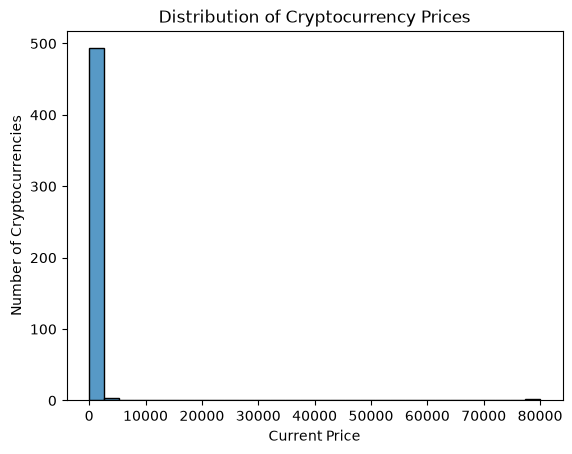

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df, x='current_price', bins=30)
plt.title('Distribution of Cryptocurrency Prices')
plt.xlabel('Current Price')
plt.ylabel('Number of Cryptocurrencies')
plt.show()

# 2. Market Cap of top cryptocurrencies
Because market cap can be highly skewed, take the top 10/20.

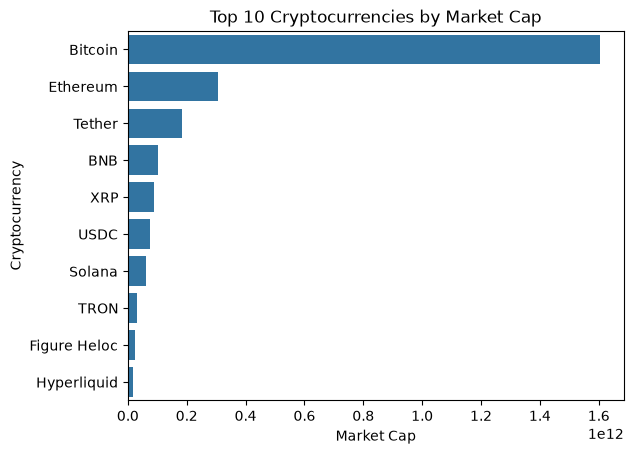

In [75]:
top_10 = df.nlargest(10, 'market_cap')

sns.barplot(data=top_10, x='market_cap', y='name')
plt.title('Top 10 Cryptocurrencies by Market Cap')
plt.xlabel('Market Cap')
plt.ylabel('Cryptocurrency')
plt.show()

# 3. Current Price vs Market Cap
Useful for understanding whether expensive coins also have high market capitalization.

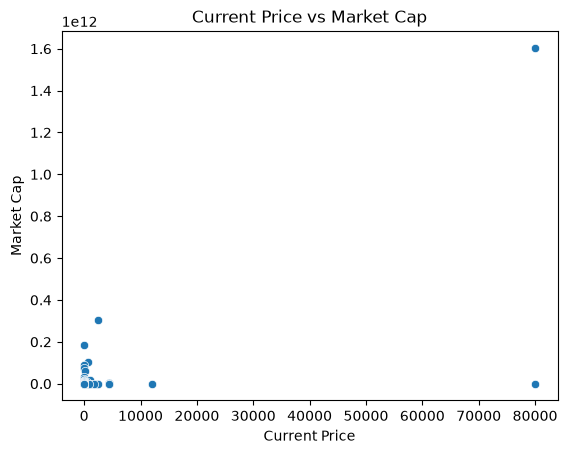

In [76]:
sns.scatterplot(
    data=df,
    x='current_price',
    y='market_cap'
)

plt.title('Current Price vs Market Cap')
plt.xlabel('Current Price')
plt.ylabel('Market Cap')
plt.show()

# 4. 24-hour price change

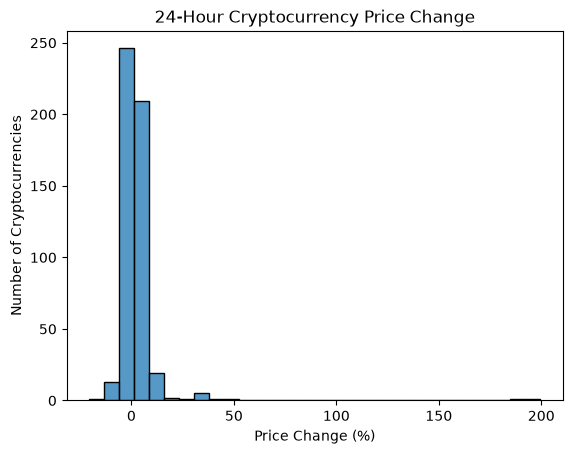

In [77]:
sns.histplot(
    data=df,
    x='price_change_percentage_24h',
    bins=30
)

plt.title('24-Hour Cryptocurrency Price Change')
plt.xlabel('Price Change (%)')
plt.ylabel('Number of Cryptocurrencies')
plt.show()

# 5. Top gainers and losers

For Top gainers

c:\Users\anilr\OneDrive\Desktop\Advanced_Multi-Source_Data_Pipeline\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 29275 (\N{CJK UNIFIED IDEOGRAPH-725B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\anilr\OneDrive\Desktop\Advanced_Multi-Source_Data_Pipeline\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26469 (\N{CJK UNIFIED IDEOGRAPH-6765}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


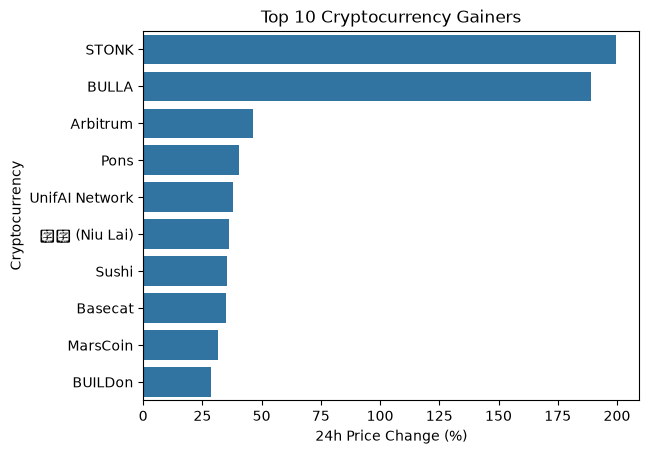

In [78]:
top_gainers = df.nlargest(10, 'price_change_percentage_24h')

sns.barplot(
    data=top_gainers,
    x='price_change_percentage_24h',
    y='name'
)

plt.title('Top 10 Cryptocurrency Gainers')
plt.xlabel('24h Price Change (%)')
plt.ylabel('Cryptocurrency')
plt.show()

For losers

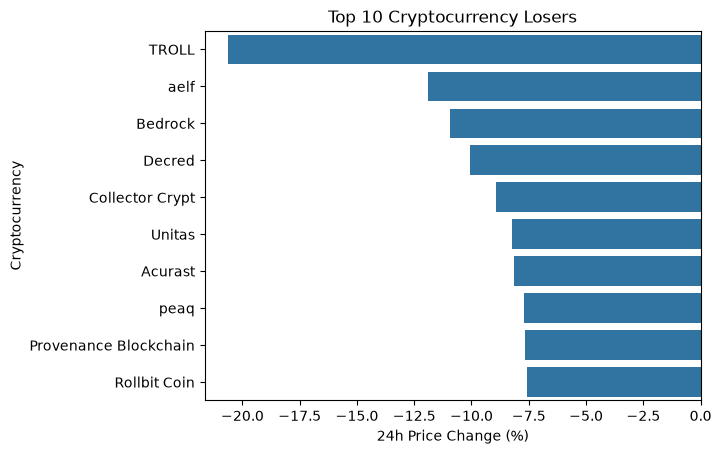

In [79]:
top_losers = df.nsmallest(10, 'price_change_percentage_24h')

sns.barplot(
    data=top_losers,
    x='price_change_percentage_24h',
    y='name'
)

plt.title('Top 10 Cryptocurrency Losers')
plt.xlabel('24h Price Change (%)')
plt.ylabel('Cryptocurrency')
plt.show()

# 6. Trading volume

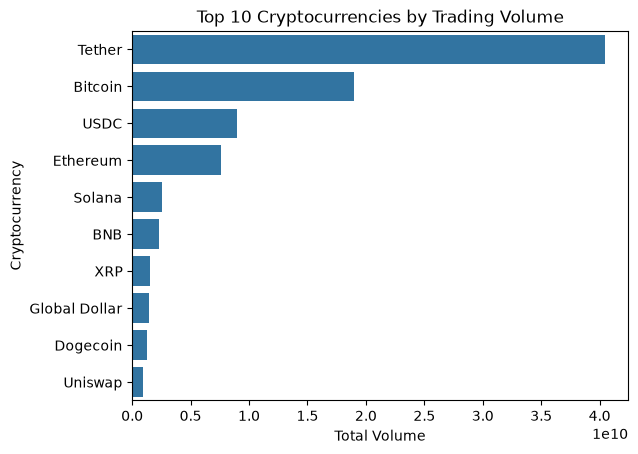

In [80]:
top_volume = df.nlargest(10, 'total_volume')

sns.barplot(
    data=top_volume,
    x='total_volume',
    y='name'
)

plt.title('Top 10 Cryptocurrencies by Trading Volume')
plt.xlabel('Total Volume')
plt.ylabel('Cryptocurrency')
plt.show()

# 7. Market Cap vs Trading Volume

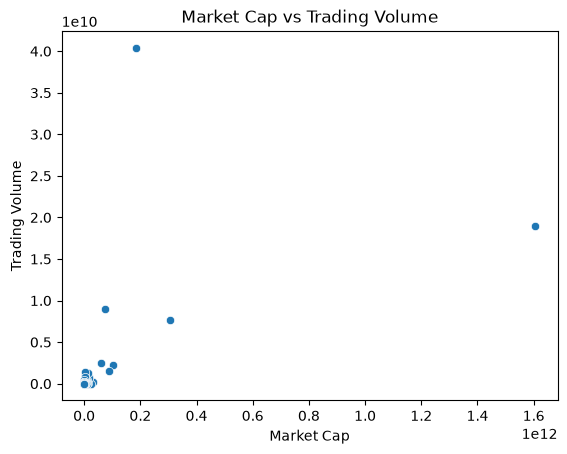

In [81]:
sns.scatterplot(
    data=df,
    x='market_cap',
    y='total_volume'
)

plt.title('Market Cap vs Trading Volume')
plt.xlabel('Market Cap')
plt.ylabel('Trading Volume')
plt.show()

# 8. Correlation heatmap

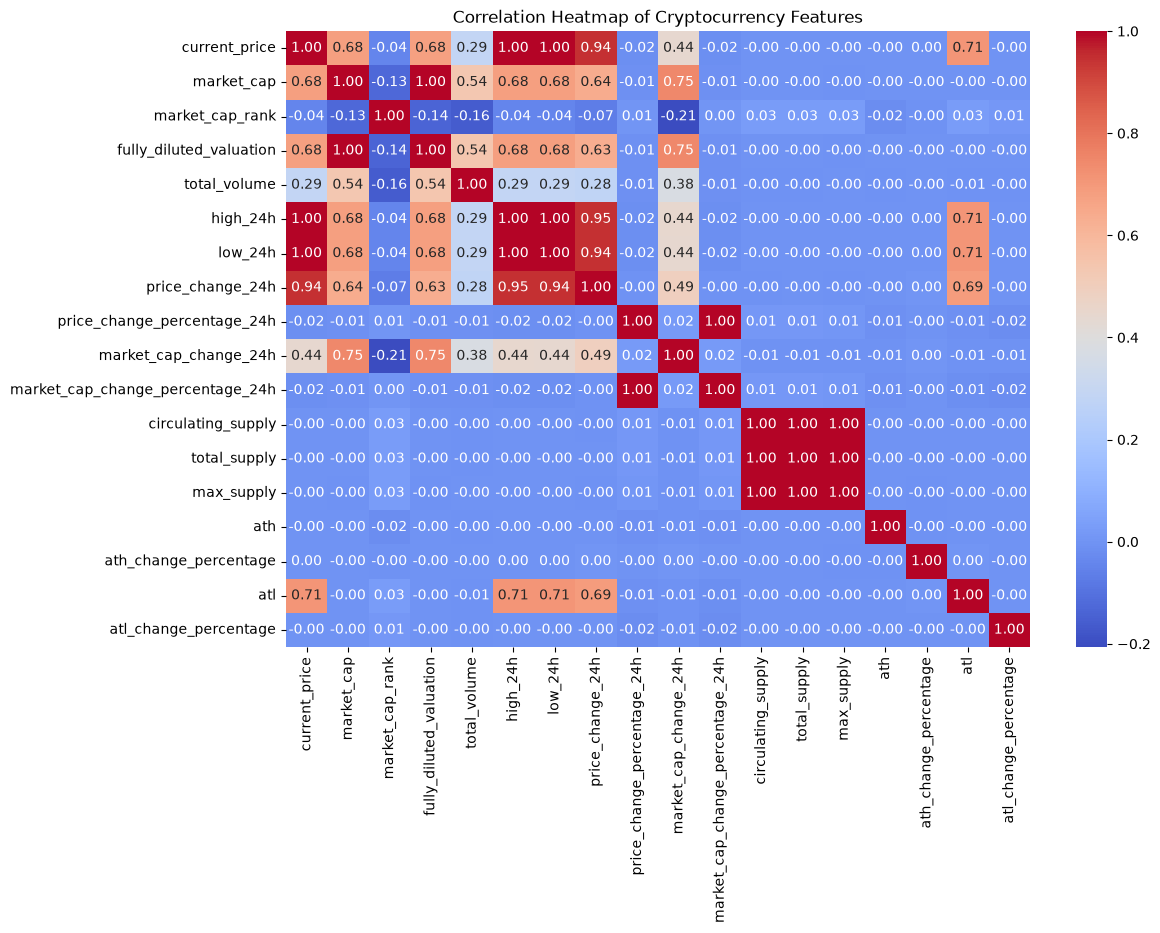

In [83]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Cryptocurrency Features')
plt.show()

# 9. Boxplots for detecting outliers

current_price

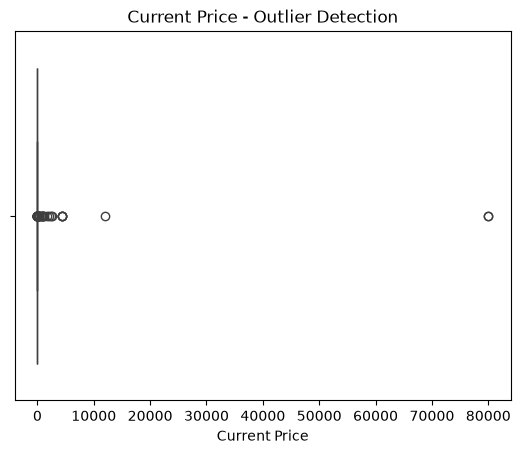

In [84]:
sns.boxplot(data=df, x='current_price')

plt.title('Current Price - Outlier Detection')
plt.xlabel('Current Price')
plt.show()

# For market_cap

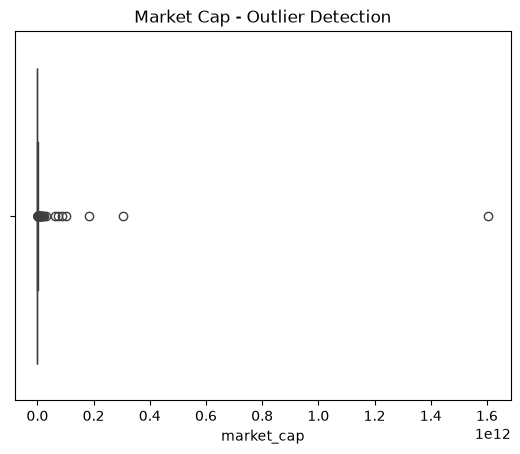

In [85]:
sns.boxplot(data=df, x='market_cap')
plt.title('Market Cap - Outlier Detection')
plt.show()

# 10. Supply analysis

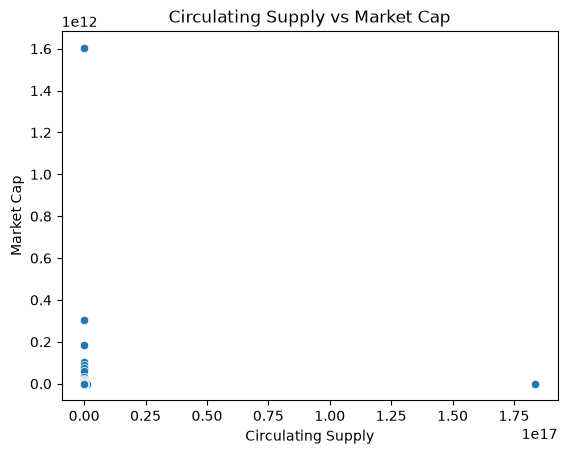

In [86]:
sns.scatterplot(
    data=df,
    x='circulating_supply',
    y='market_cap'
)

plt.title('Circulating Supply vs Market Cap')
plt.xlabel('Circulating Supply')
plt.ylabel('Market Cap')
plt.show()